# ACC_Modeling — Stage 2 Final (SINDy Benchmark)
**`stage2final`: Whole-Vehicle Planar Force & Friction-Ellipse Identification ($[\delta, \dot{\delta}, a_y, a_x, v, \eta_P] \to \dot{r}$)**

This notebook establishes the final **Stage 2 SINDy** baseline benchmark for direct comparison with **Stage 3** (single-wheel physics modeling) and **Stage 4** (full-chassis nonlinear modeling).

### Scope & Configuration
- **Vehicle**: Audi R8 LMS GT3 Evo II (`configs/cars/audi_r8_gt3_evo2/vehicle.yaml`)
- **Setup**: `R8_A` (`configs/cars/audi_r8_gt3_evo2/setups/Barcelona/r8_A.yaml`)
- **Telemetry**: 10L Hotlap Baseline (`data/calibration/baseline.csv`, 200 Hz, fixed 10L fuel, no race laps)
- **Curation**: Savitzky-Golay (`window=41, poly=3`) smoothing & analytical differentiation ($\dot{r}, \dot{a}_y$), tire-pressure grip factor $\eta_P(t)$
- **Regression**: PySINDy `STLSQ` (`threshold=0.02`, `alpha=0.05`) on the 8-term physics-informed planar force library

In [1]:
import os
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown

if Path.cwd().name == "notebooks":
    os.chdir("..")

from src.cli import run_pipeline

print("Working directory:", Path.cwd())

Working directory: /mnt/c/LocalD/ACC_Modeling


## 1. Run Stage 2 Final SINDy Pipeline (GT3 10L Hotlap Baseline)

In [2]:
config_path = "configs/experiments/stage2_planar_force/barcelona__audi_r8_gt3_evo2__r8_A__hotlap_10l.yaml"
report = run_pipeline(config_path)

print("Identified ODE:", report["equation"])
print(f"Samples: {report['clean_metrics']['n_samples']}")
print(f"R^2:     {report['clean_metrics']['r2']:.6f}")
print(f"RMSE:    {report['clean_metrics']['rmse']:.6f} rad/s^2")
print(f"MAE:     {report['clean_metrics']['mae']:.6f} rad/s^2")

INFO: Running experiment: stage2final_barcelona_gt3_r8_A_hotlap_10l (Audi R8 LMS GT3 Evo II @ Circuit de Barcelona-Catalunya)


INFO: Trimmed at SPEED >= 100.0 km/h (t=0.000s, 21367 -> 21367 rows)


INFO: Identified ODE: dr/dt = +1.24626 * delta +0.05807 * delta_dot -2.00643 * r -5.14308 * r/v -2.74521 * (a_y-v*r)/v +0.01659 * a_y_dot +0.00079 * a_y*|a_x|/eta_P^2 -0.19053 * delta*|delta|


INFO: Clean Practice R^2=0.3934 | RMSE=0.7554 rad/s^2


INFO: Substituting symbol N from STIXNonUnicode


INFO: Substituting symbol N from STIXNonUnicode


INFO: Artifacts saved to outputs/stage2final_barcelona_gt3_r8_A_hotlap_10l


Identified ODE: dr/dt = +1.24626 * delta +0.05807 * delta_dot -2.00643 * r -5.14308 * r/v -2.74521 * (a_y-v*r)/v +0.01659 * a_y_dot +0.00079 * a_y*|a_x|/eta_P^2 -0.19053 * delta*|delta|
Samples: 21367
R^2:     0.393390
RMSE:    0.755393 rad/s^2
MAE:     0.461052 rad/s^2


## 2. Benchmark Summary & Statistical Diagnostics

In [3]:
diag = report["clean_metrics"]["diagnostics"]
summary_df = pd.DataFrame([{
    "Experiment": report["experiment"],
    "Samples": report["clean_metrics"]["n_samples"],
    "R2": report["clean_metrics"]["r2"],
    "RMSE (rad/s^2)": report["clean_metrics"]["rmse"],
    "MAE (rad/s^2)": report["clean_metrics"]["mae"],
    "Within ±3σ (%)": diag["within_3sigma_pct"],
    "Skewness": diag["skewness"],
    "Excess Kurtosis": diag["excess_kurtosis"],
}])
display(Markdown("### Stage 2 Final Benchmark Metrics"))
display(summary_df)

display(Markdown("### Block Bootstrap Parameter Significance (500 resamples, 2.0s blocks)"))
display(pd.DataFrame(report["bootstrap"]["terms"]))

display(Markdown("### Type-I Error (Omission) Sweep"))
display(pd.DataFrame(diag["omission_sweep"]))

### Stage 2 Final Benchmark Metrics

,Experiment,Samples,R2,RMSE (rad/s^2),MAE (rad/s^2),Within ±3σ (%),Skewness,Excess Kurtosis
0,stage2final_barcelona_gt3_r8_A_hotlap_10l,21367,0.39339,0.755393,0.461052,97.96883,-0.81689,11.976196


### Block Bootstrap Parameter Significance (500 resamples, 2.0s blocks)

,name,point_estimate,boot_mean,boot_std,ci_95_low,ci_95_high,t_statistic,p_value
0,delta,1.246258,1.351584,0.409155,0.704513,2.236372,3.045931,2.442323e-03
1,delta_dot,0.058070,0.048180,0.023010,0.000215,0.092873,2.523622,1.192464e-02
2,r,-2.006429,-2.162101,0.735408,-3.673393,-0.918199,-2.728320,6.590304e-03
3,r/v,-5.143082,-5.566884,14.484923,-36.439009,23.866433,-0.355065,7.226913e-01
4,(a_y-v*r)/v,-2.745207,-2.569623,0.688252,-4.001933,-1.182168,-3.988665,7.639609e-05
5,a_y_dot,0.016586,0.017108,0.002996,0.010893,0.022490,5.535408,5.024818e-08
6,a_y*|a_x|/eta_P^2,0.000790,0.000835,0.000523,-0.000219,0.001829,1.510558,1.315340e-01
7,delta*|delta|,-0.190535,-0.205218,0.124484,-0.458227,0.056044,-1.530601,1.265017e-01


### Type-I Error (Omission) Sweep

,z_threshold,expected_omissions,actual_omissions,expected_pct,actual_pct
0,1.0,6779.973622,4047,31.731051,18.940422
1,2.0,972.204139,1109,4.550026,5.190247
2,2.5,265.363838,672,1.241933,3.145037
3,3.0,57.686542,434,0.269980,2.031170
4,3.5,9.941171,278,0.046526,1.301072
5,4.0,1.353439,177,0.006334,0.828380
6,5.0,0.012250,79,0.000057,0.369729


## 3. Yaw Acceleration Fit & Residual Gaussianity Diagnostics

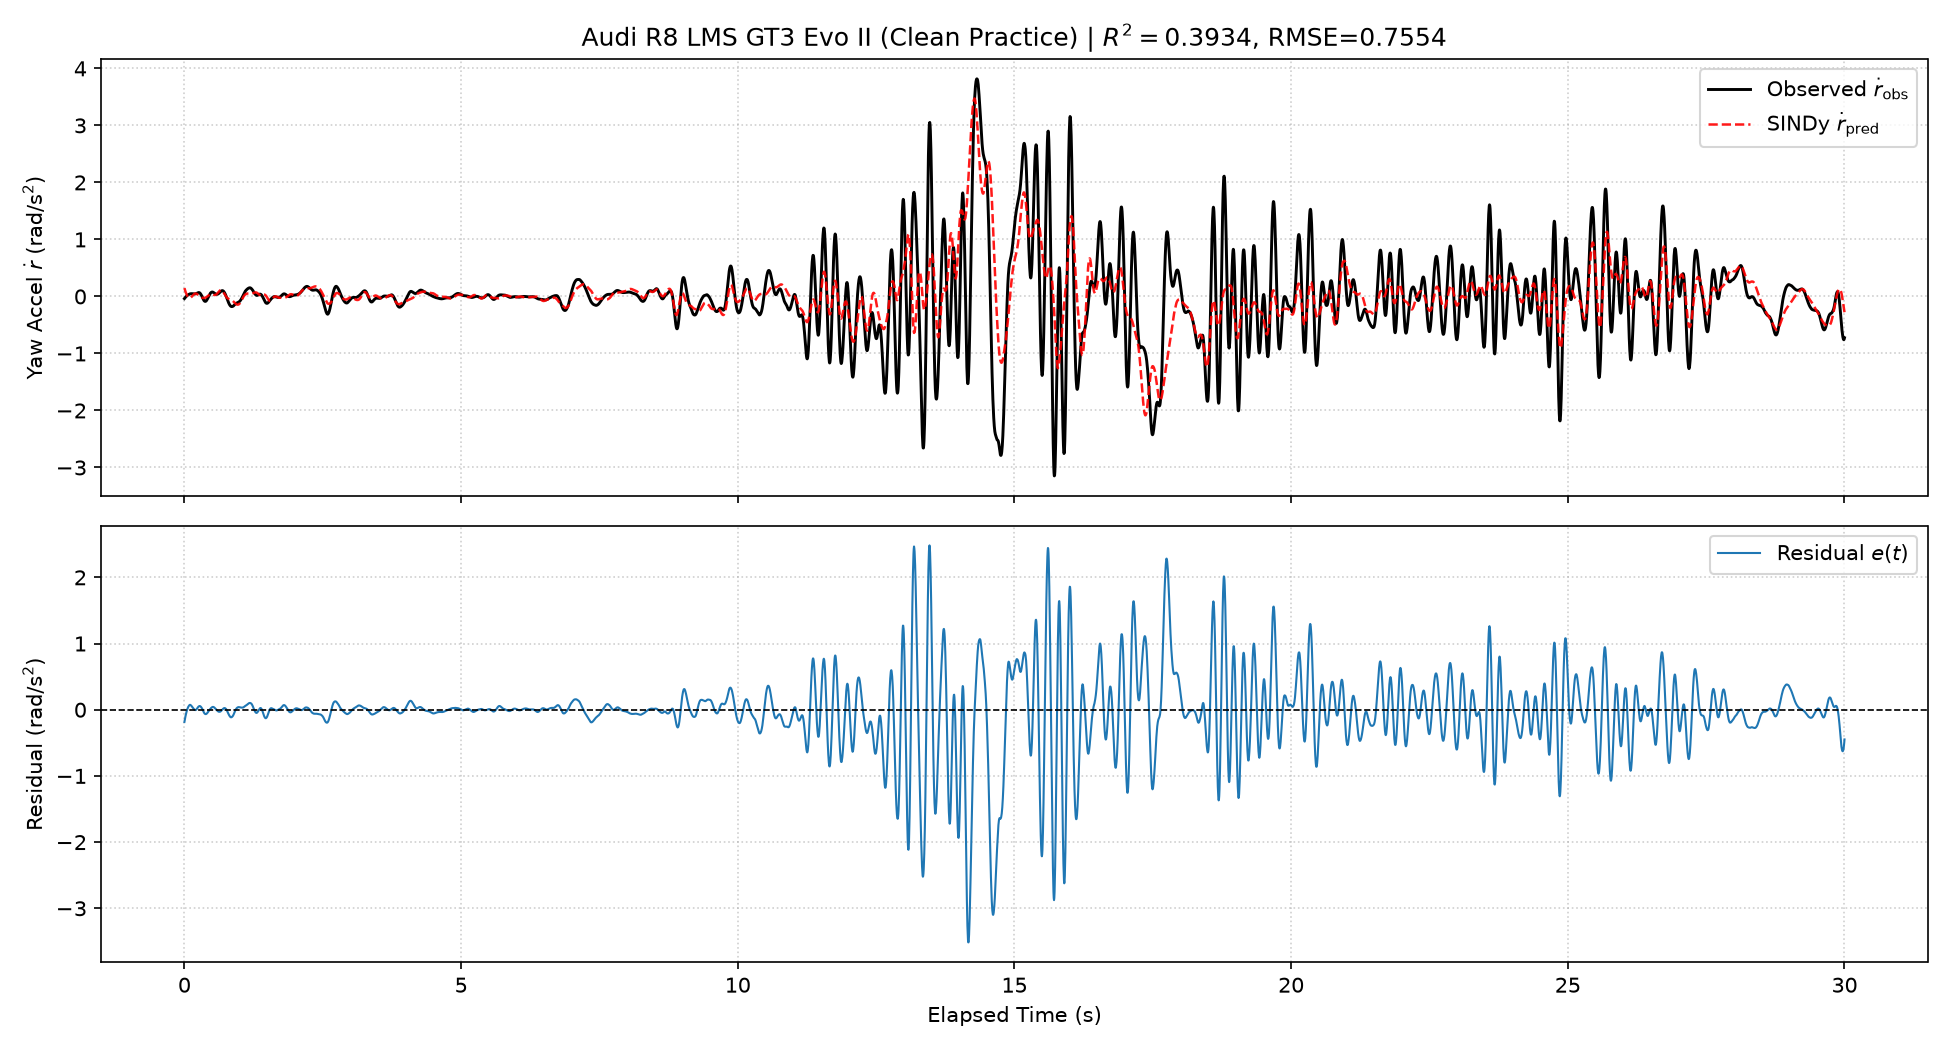

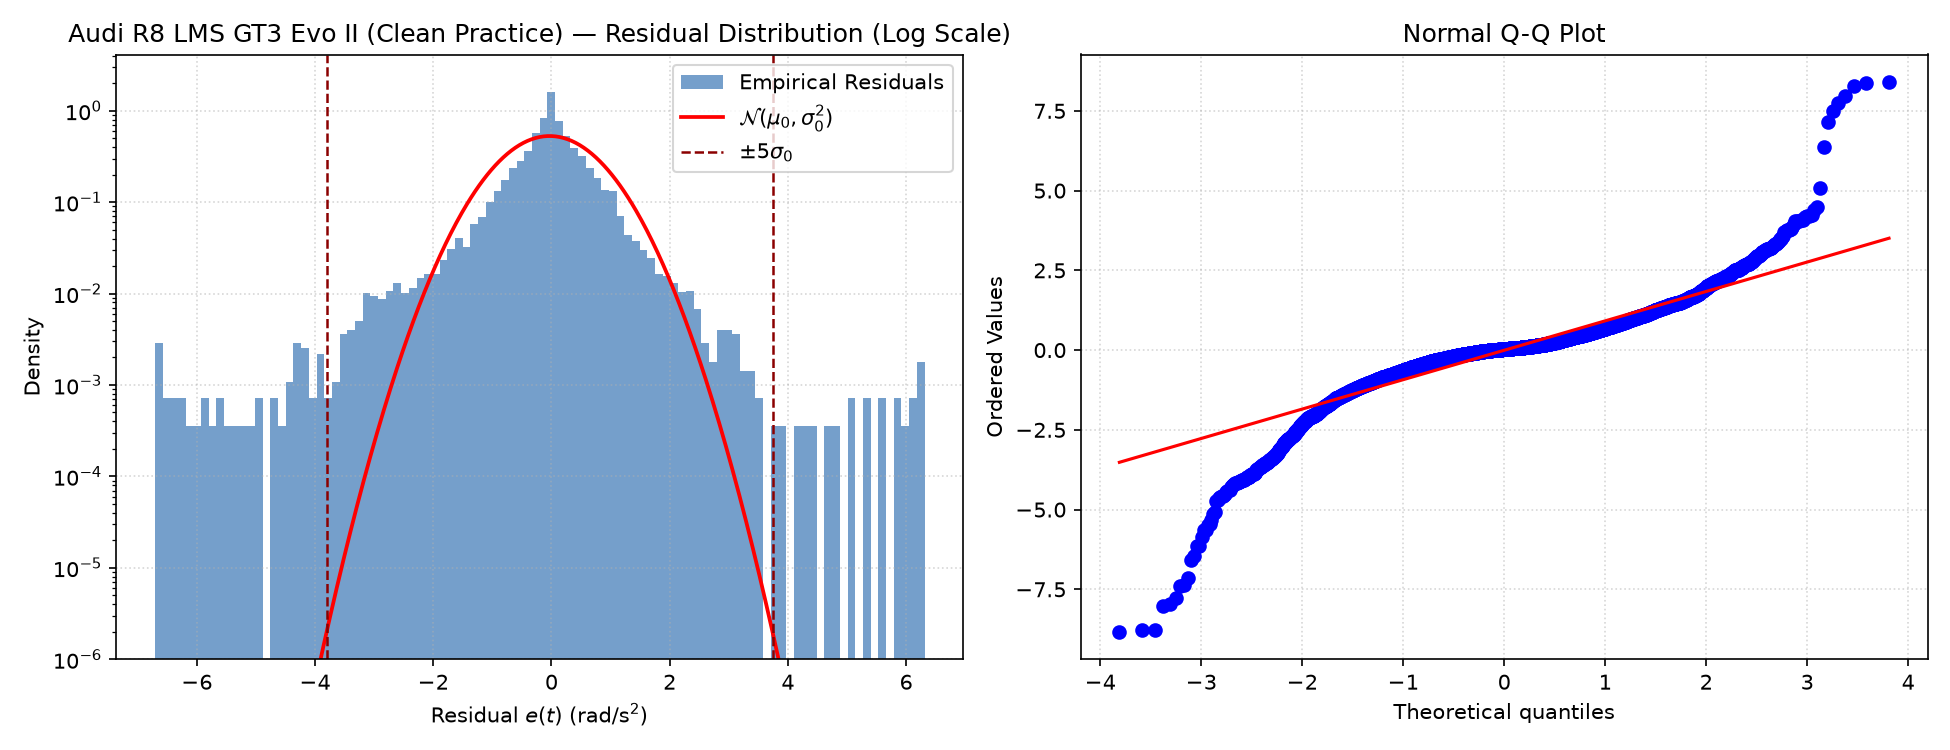

In [4]:
out_dir = Path("outputs") / report["experiment"]
for img_name in ["clean_yaw_fit.png", "clean_residuals_qq.png"]:
    display(Image(filename=str(out_dir / img_name)))